Laine Goldmacher

Group 5

Penalized Linear Model and a Support Vector Machine.

In [13]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV, GroupKFold, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay, confusion_matrix
from sklearn.base import clone
%run data_preparation.ipynb

Python: 3.14.4
pandas: 3.1.1
Working directory: /Users/lainegoldmacher/DS4021-Final-Project
Official Data/ exists: True
Data/ already exists: SKIPPING generation to protect the reporting set.
Dataset is correctly organized.
Total: 287,257
Training: 229,015 (79.72%)
Reporting: 58,242 (20.28%)
No reporting-set measurements were opened or modified.


In [14]:
X_train

,heart_rate,hand_temp,hand_acc16_x,hand_acc16_y,hand_acc16_z,hand_acc6_x,hand_acc6_y,hand_acc6_z,hand_gyro_x,hand_gyro_y,...,ankle_acc16_z,ankle_acc6_x,ankle_acc6_y,ankle_acc6_z,ankle_gyro_x,ankle_gyro_y,ankle_gyro_z,ankle_mag_x,ankle_mag_y,ankle_mag_z
293,101.0,30.375,2.29090,7.14240,5.82342,2.26966,7.66268,5.78846,-0.238241,0.011214,...,-0.059173,9.60196,-1.73721,0.356632,-0.035392,-0.052422,-0.004882,-60.3407,-35.784200,-58.611900
294,101.0,30.375,2.28661,7.67154,5.59065,2.31412,7.72263,5.63727,-0.058076,-0.015138,...,0.133607,9.57165,-1.79779,0.296447,0.037129,0.003524,-0.001803,-60.8735,-37.535300,-58.254900
295,101.0,30.375,2.16379,8.28577,6.27951,2.18617,7.83003,6.45261,0.293617,0.001592,...,-0.137150,9.60175,-1.79777,0.311422,0.004155,0.010500,0.007628,-60.6611,-36.769000,-58.372300
296,101.0,30.375,2.27181,8.09419,6.16631,2.24558,7.99547,6.18037,0.233565,-0.149083,...,0.095004,9.58667,-1.78266,0.296318,-0.004238,-0.011963,0.006608,-61.1142,-36.637900,-58.738500
297,101.0,30.375,2.43405,6.76050,5.67290,2.68729,6.84442,6.09184,-0.140184,-0.278145,...,-0.098395,9.64664,-1.76756,0.265681,0.015364,-0.036449,-0.012476,-60.7757,-36.868800,-58.867500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
228959,161.0,25.125,4.89403,6.56286,6.94201,4.77218,6.66398,6.87534,-0.222332,-0.106463,...,-1.913640,9.41379,-2.11768,-1.517910,-0.037467,0.015140,-0.001103,-46.1741,-0.554862,-0.171827
228960,162.0,25.125,4.34732,6.90337,6.35537,4.39582,6.96850,6.61834,-0.303158,-0.255639,...,-2.183610,9.35297,-2.25402,-1.683640,-0.002293,-0.004692,0.009044,-45.5269,-0.843791,0.114449
228961,162.0,25.125,4.63360,6.51829,5.97608,4.59745,6.36248,6.10604,0.036255,-0.390307,...,-1.951160,9.42845,-2.05728,-1.609000,-0.026705,-0.044173,-0.037867,-45.6445,-1.094160,0.539822
228962,162.0,25.125,4.88770,6.55150,5.67187,4.88192,6.52618,5.71277,-0.207075,-0.272917,...,-2.299280,9.50285,-2.11797,-1.775680,-0.039035,-0.032119,-0.017305,-46.0300,-1.334520,-0.170416


In [15]:
X_train.columns

Index(['heart_rate', 'hand_temp', 'hand_acc16_x', 'hand_acc16_y',
       'hand_acc16_z', 'hand_acc6_x', 'hand_acc6_y', 'hand_acc6_z',
       'hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z', 'hand_mag_x', 'hand_mag_y',
       'hand_mag_z', 'chest_temp', 'chest_acc16_x', 'chest_acc16_y',
       'chest_acc16_z', 'chest_acc6_x', 'chest_acc6_y', 'chest_acc6_z',
       'chest_gyro_x', 'chest_gyro_y', 'chest_gyro_z', 'chest_mag_x',
       'chest_mag_y', 'chest_mag_z', 'ankle_temp', 'ankle_acc16_x',
       'ankle_acc16_y', 'ankle_acc16_z', 'ankle_acc6_x', 'ankle_acc6_y',
       'ankle_acc6_z', 'ankle_gyro_x', 'ankle_gyro_y', 'ankle_gyro_z',
       'ankle_mag_x', 'ankle_mag_y', 'ankle_mag_z'],
      dtype='str')

In [16]:
SEED = 42
np.random.seed(SEED)

In [18]:
imu = ['temp', 'acc16_x', 'acc16_y', 'acc16_z',
    'acc6_x', 'acc6_y', 'acc6_z',
    'gyro_x', 'gyro_y', 'gyro_z',
    'mag_x', 'mag_y', 'mag_z',
    'orient_1', 'orient_2', 'orient_3', 'orient_4']

COLS = (['timestamp', 'activity_id', 'heart_rate']
        + [f'hand_{c}' for c in imu]
        + [f'chest_{c}' for c in imu]
        + [f'ankle_{c}' for c in imu])

assert len(COLS) == 54

ACTIVITIES = {1: 'lying', 2: 'sitting', 3: 'standing', 4: 'walking', 5: 'running',
    6: 'cycling', 7: 'nordic_walking', 9: 'watching_tv',
    10: 'computer_work', 11: 'car_driving', 12: 'ascending_stairs',
    13: 'descending_stairs', 16: 'vacuum_cleaning', 17: 'ironing',
    18: 'folding_laundry', 19: 'house_cleaning', 20: 'playing_soccer',
    24: 'rope_jumping'}

cwd = Path.cwd()
ROOT = cwd if (cwd / 'Data' / 'training_set').exists() else cwd.parent
TRAIN_DIR = ROOT / 'Data' / 'training_set'
training_set = sorted(TRAIN_DIR.glob('subject*.csv.gz'))

frames = []
for path in training_set:
    frame = pd.read_csv(path, compression='gzip', header=None, names=COLS)
    frame['subject'] = int(path.name[7:10])
    frames.append(frame)

train = pd.concat(frames, ignore_index=True)
del frames, frame
print('Training rows, including transient labels:', len(train))
train = train.loc[train['activity_id'].ne(0)].copy()
train['activity'] = train['activity_id'].map(ACTIVITIES)
if train['activity'].isna().any():
    raise ValueError('Unexpected activity code found in training data.')

exclude = ['timestamp', 'subject', 'activity_id', 'activity']
exclude += [c for c in train.columns if 'orient' in c]
X = train.drop(columns=exclude).copy()
y = train['activity'].copy()
groups = train['subject'].copy()
assert X.shape[1] == 40, f'Expected 40 sensor features, got {X.shape[1]}'
assert X.select_dtypes(exclude='number').empty, 'All predictors must be numeric.'

print(f'Labeled training examples: {len(X):,}')
print('Sensor predictors:', X.shape[1])
print('Distinct activities:', y.nunique())
print('Distinct training subjects:', groups.nunique())
print('\nActivities and counts:')
display(y.value_counts().rename_axis('Activity').to_frame('Rows'))

Training rows, including transient labels: 229015
Labeled training examples: 153,715
Sensor predictors: 40
Distinct activities: 12
Distinct training subjects: 7

Activities and counts:


,Rows
Activity,
ironing,18572
walking,17781
nordic_walking,16056
lying,14744
standing,14469
cycling,14191
vacuum_cleaning,13500
sitting,13093
running,9820


activity,ascending_stairs,cycling,descending_stairs,ironing,lying,nordic_walking,rope_jumping,running,sitting,standing,vacuum_cleaning,walking
subject,,,,,,,,,,,,
101,1589,2358,1490,2357,2719,2026,1291,2126,2348,2172,2295,2226
102,1734,2511,1521,2888,2343,2974,1326,924,2234,2557,2068,3254
105,1428,2457,1272,3304,2370,2627,774,2465,2686,2213,2445,3203
106,1330,2049,1128,3774,2334,2668,25,2283,2304,2436,2108,2572
107,1765,2268,1162,2950,2561,2872,0,369,1228,2575,2155,3372
108,1168,2548,966,3299,2417,2889,881,1653,2293,2516,2429,3154
109,0,0,0,0,0,0,639,0,0,0,0,0


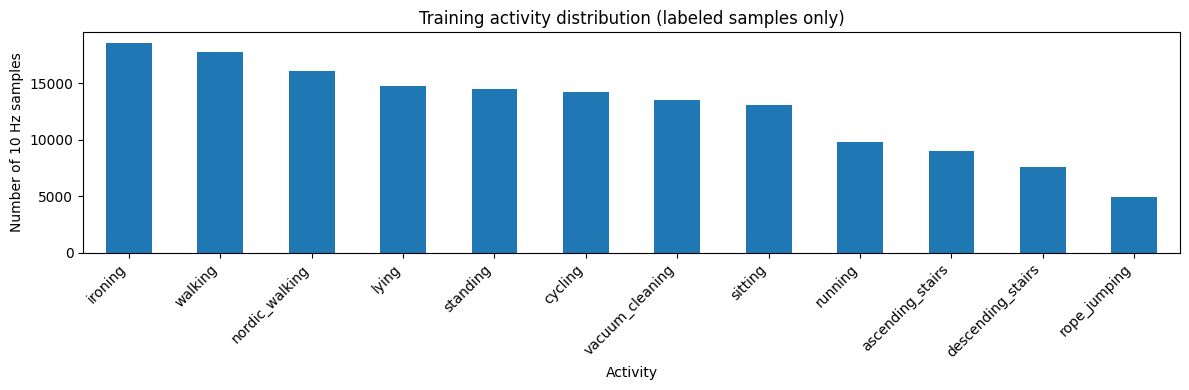

In [19]:
# distributions

counts = pd.crosstab(groups, y)
display(counts)
plt.figure(figsize=(12, 4))
y.value_counts().plot.bar()
plt.title('Training activity distribution (labeled samples only)')
plt.xlabel('Activity')
plt.ylabel('Number of 10 Hz samples')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [20]:
# Validation, metrics, and preprocessing choices

cv = GroupKFold(n_splits=5)
fold_membership = []
for fold, (train_idx, val_idx) in enumerate(cv.split(X, y, groups), 1):
    train_subjects = sorted(groups.iloc[train_idx].unique().tolist())
    val_subjects = sorted(groups.iloc[val_idx].unique().tolist())
    assert set(train_subjects).isdisjoint(val_subjects)
    fold_membership.append({
        'Fold': fold,
        'Training participants': ', '.join(map(str, train_subjects)),
        'Validation participants': ', '.join(map(str, val_subjects)),
        'Validation rows': len(val_idx)
    })
display(pd.DataFrame(fold_membership))

scoring = {
    'macro_f1': 'f1_macro',
    'balanced_accuracy': 'balanced_accuracy',
    'accuracy': 'accuracy'
}

,Fold,Training participants,Validation participants,Validation rows
0,1,"101, 102, 106, 107, 108, 109",105,27244
1,2,"101, 105, 106, 107, 108, 109",102,26334
2,3,"101, 102, 105, 106, 107, 109",108,26213
3,4,"101, 102, 105, 107, 108","106, 109",25650
4,5,"102, 105, 106, 108, 109","101, 107",48274


We use the same GroupKFold(n_splits=5) folds for both models, grouping by participant. Group-based validation matches the deployment objective, whereas random stratified folds would mix near-duplicate adjacent sensor readings from a participant between training and validation.

Both linear models require feature scaling. Some sensor readings (especially heart rate) are missing in the raw files. A median imputer followed by standardization is fitted separately on each training fold using a Pipeline; this prevents a validation fold from influencing preprocessing. We deliberately do not apply the prior preparation notebook's global forward/backward fill, because it would cross fold boundaries under a different splitting strategy.

Primary selection metric: macro-F1 (treats activity classes comparably).
Other metrics: balanced accuracy and ordinary accuracy. Macro-F1 is useful when the activity classes are imbalanced, while balanced accuracy averages class recall. Some training participants did not perform every activity, so generalization to unseen subjects may be challenging.

In [21]:
# Model 1: L2-penalized Logistic Regression

logistic_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        penalty='l2', solver='lbfgs', max_iter=1500, random_state=SEED
    ))
])
logistic_grid = {
    'model__C': [0.01, 0.1, 1.0, 10.0],
    'model__class_weight': [None, 'balanced']
}

logistic_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_grid,
    cv=cv,
    scoring=scoring,
    refit='macro_f1',
    n_jobs=-1,
    return_train_score=False,
    error_score='raise'
)

# The groups argument is essential: it prevents mixing participants across folds.
logistic_search.fit(X, y, groups=groups)
print('Best hyperparameters:', logistic_search.best_params_)
print('Best cross-validated macro-F1:', round(logistic_search.best_score_, 4))

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarnin

Best hyperparameters: {'model__C': 0.01, 'model__class_weight': 'balanced'}
Best cross-validated macro-F1: 0.3922


In [22]:
# Model 2 SVM

svm_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LinearSVC(
        dual=False, max_iter=5000, random_state=SEED
    ))
])
svm_grid = {
    'model__C': [0.01, 0.1, 1.0, 10.0],
    'model__class_weight': [None, 'balanced']
}
svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_grid,
    cv=cv,
    scoring=scoring,
    refit='macro_f1',
    n_jobs=-1,
    return_train_score=False,
    error_score='raise'
)
svm_search.fit(X, y, groups=groups)
print('Best hyperparameters:', svm_search.best_params_)
print('Best cross-validated macro-F1:', round(svm_search.best_score_, 4))

Best hyperparameters: {'model__C': 0.01, 'model__class_weight': 'balanced'}
Best cross-validated macro-F1: 0.366


In [23]:
# Hyperparameter combinations and cross-validation scores

def grid_table(search, model_name):
    results = pd.DataFrame(search.cv_results_)
    cols = ['params', 'mean_test_macro_f1', 'std_test_macro_f1',
            'mean_test_balanced_accuracy', 'mean_test_accuracy', 'rank_test_macro_f1']
    out = results[cols].copy()
    out.insert(0, 'Model', model_name)
    return out.sort_values('rank_test_macro_f1')

all_results = pd.concat([
    grid_table(logistic_search, 'L2 Logistic Regression'),
    grid_table(svm_search, 'Linear SVM')
], ignore_index=True)
with pd.option_context('display.max_colwidth', 130, 'display.max_rows', 50):
    display(all_results.round(4))

,Model,params,mean_test_macro_f1,std_test_macro_f1,mean_test_balanced_accuracy,mean_test_accuracy,rank_test_macro_f1
0,L2 Logistic Regression,"{'model__C': 0.01, 'model__class_weight': 'balanced'}",0.3922,0.1047,0.4402,0.4543,1
1,L2 Logistic Regression,"{'model__C': 0.01, 'model__class_weight': None}",0.3843,0.1029,0.4301,0.4563,2
2,L2 Logistic Regression,"{'model__C': 0.1, 'model__class_weight': 'balanced'}",0.3422,0.1286,0.3915,0.4064,3
3,L2 Logistic Regression,"{'model__C': 0.1, 'model__class_weight': None}",0.3377,0.1270,0.3884,0.4116,4
4,L2 Logistic Regression,"{'model__C': 1.0, 'model__class_weight': 'balanced'}",0.3341,0.1272,0.3831,0.3967,5
5,L2 Logistic Regression,"{'model__C': 10.0, 'model__class_weight': 'balanced'}",0.3320,0.1263,0.3808,0.3941,6
6,L2 Logistic Regression,"{'model__C': 1.0, 'model__class_weight': None}",0.3293,0.1239,0.3791,0.4003,7
7,L2 Logistic Regression,"{'model__C': 10.0, 'model__class_weight': None}",0.3275,0.1231,0.3767,0.3974,8
8,Linear SVM,"{'model__C': 0.01, 'model__class_weight': 'balanced'}",0.3660,0.1317,0.4142,0.4362,1
9,Linear SVM,"{'model__C': 0.1, 'model__class_weight': 'balanced'}",0.3541,0.1391,0.4033,0.4244,2
